In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ecommerce_sales_raw.csv")

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], dayfirst=True
)

print(df.head())

  Order_ID Order_Date Product_Name  Quantity       City Payment_Method  \
0  ORD0001 2025-04-13       Laptop         1    Chennai    Net Banking   
1  ORD0002 2026-03-12   Headphones         3     Mumbai            UPI   
2  ORD0003 2025-09-28      Speaker         1      Delhi            COD   
3  ORD0004 2025-04-17       Tablet         5     Mumbai    Credit Card   
4  ORD0005 2025-03-13      Monitor         2  Bengaluru    Credit Card   

  Order_Status  Discount_Percent  Unit_Price     Category  
0    Delivered                 0       65000  Electronics  
1     Returned                 5        2500  Accessories  
2     Returned                 5        4000  Electronics  
3    Delivered                 5       22000  Electronics  
4    Delivered                10       12000  Electronics  


In [4]:
print(df.columns)

Index(['Order_ID', 'Order_Date', 'Product_Name', 'Quantity', 'City',
       'Payment_Method', 'Order_Status', 'Discount_Percent', 'Unit_Price',
       'Category'],
      dtype='str')


In [5]:
print(df["Product_Name"].value_counts())

Product_Name
Laptop        3
Speaker       2
Tablet        2
Keyboard      2
Headphones    1
Monitor       1
Webcam        1
Smartwatch    1
Smartphone    1
Name: count, dtype: int64


In [6]:
revenue_by_region = df.groupby("City")["Revenue"].sum()

print(revenue_by_region)

KeyError: 'Column not found: Revenue'

In [7]:
df["Revenue"] = (
    df["Quantity"] *
    df["Unit_Price"] *
    (1 - df["Discount_Percent"] / 100)
)

print(df[["Product_Name", "Quantity", "Unit_Price",
          "Discount_Percent", "Revenue"]])

   Product_Name  Quantity  Unit_Price  Discount_Percent   Revenue
0        Laptop         1       65000                 0   65000.0
1    Headphones         3        2500                 5    7125.0
2       Speaker         1        4000                 5    3800.0
3        Tablet         5       22000                 5  104500.0
4       Monitor         2       12000                10   21600.0
5        Tablet         2       22000                20   35200.0
6        Webcam         2        3500                20    5600.0
7      Keyboard         3        1500                 0    4500.0
8        Laptop         5       65000                 0  325000.0
9        Laptop         1       65000                 5   61750.0
10      Speaker         4        4000                 0   16000.0
11     Keyboard         1        1500                10    1350.0
12   Smartwatch         4        7000                20   22400.0
13   Smartphone         1       30000                 5   28500.0


In [8]:
revenue_by_region = df.groupby("City")["Revenue"].sum()

print(revenue_by_region)

City
 chennai          35200.0
Bengaluru         21600.0
Chennai           65000.0
Delhi              3800.0
Hyderabad          4500.0
Mumbai           111625.0
Pune             325000.0
Vijayawada        39750.0
Visakhapatnam     95850.0
Name: Revenue, dtype: float64


In [9]:
region_summary = df.groupby("City").agg(
    Average_Revenue=("Revenue", "mean"),
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Revenue", "sum")
)

region_summary = region_summary.sort_values(
    by="Total_Revenue",
    ascending=False
)

print(region_summary)

               Average_Revenue  Order_Count  Total_Revenue
City                                                      
Pune                  325000.0            1       325000.0
Mumbai                 55812.5            2       111625.0
Visakhapatnam          31950.0            3        95850.0
Chennai                65000.0            1        65000.0
Vijayawada             13250.0            3        39750.0
 chennai               35200.0            1        35200.0
Bengaluru              21600.0            1        21600.0
Hyderabad               4500.0            1         4500.0
Delhi                   3800.0            1         3800.0


In [10]:
units_sold = df.groupby("Product_Name")["Quantity"].sum()

print(units_sold.sort_values(ascending=False))

Product_Name
Laptop        7
Tablet        7
Speaker       5
Smartwatch    4
Keyboard      4
Headphones    3
Monitor       2
Webcam        2
Smartphone    1
Name: Quantity, dtype: int64


In [11]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

c_table = df[numeric_columns].corr()

print(c_table)

                  Quantity  Discount_Percent  Unit_Price   Revenue
Quantity          1.000000         -0.118644   -0.063237  0.523170
Discount_Percent -0.118644          1.000000   -0.361061 -0.331975
Unit_Price       -0.063237         -0.361061    1.000000  0.674244
Revenue           0.523170         -0.331975    0.674244  1.000000


In [12]:
correlation = df["Quantity"].corr(df["Revenue"])

print("Units and Revenue Correlation:", correlation)

Units and Revenue Correlation: 0.5231696871364978


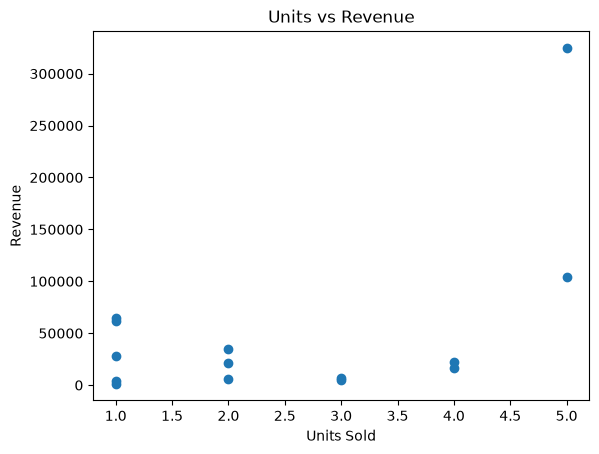

In [13]:
plt.scatter(df["Quantity"], df["Revenue"])

plt.xlabel("Units Sold")
plt.ylabel("Revenue")
plt.title("Units vs Revenue")

plt.show()

In [14]:
df["Month"] = df["Order_Date"].dt.month

monthly_revenue = df.groupby("Month")["Revenue"].sum()

print(monthly_revenue)

Month
1      63700.0
3      51125.0
4     495850.0
5       4500.0
8      61750.0
9       9400.0
11     16000.0
Name: Revenue, dtype: float64


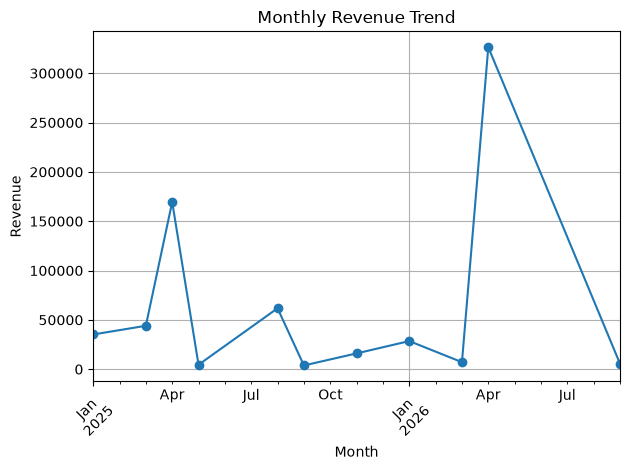

In [15]:
df["Month"] = df["Order_Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Revenue"].sum()

monthly_revenue.plot(kind="line", marker="o")

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue Trend")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

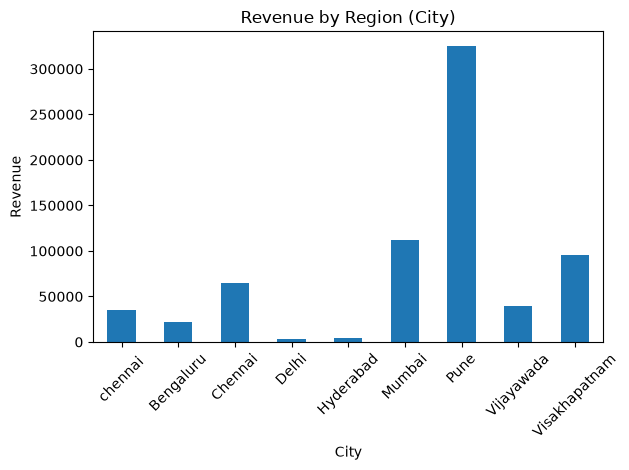

In [16]:
region_revenue = df.groupby("City")["Revenue"].sum()

region_revenue.plot(kind="bar")

plt.xlabel("City")
plt.ylabel("Revenue")
plt.title("Revenue by Region (City)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [18]:
highest_revenue = df.sort_values(
    by="Revenue",
    ascending=False
)

print(highest_revenue[
    ["Order_ID", "Product_Name", "City", "Revenue"]
]).head(5)

   Order_ID Product_Name           City   Revenue
8   ORD0009       Laptop           Pune  325000.0
3   ORD0004       Tablet         Mumbai  104500.0
0   ORD0001       Laptop        Chennai   65000.0
9   ORD0010       Laptop  Visakhapatnam   61750.0
5   ORD0006       Tablet       chennai    35200.0
13  ORD0014   Smartphone  Visakhapatnam   28500.0
12  ORD0013   Smartwatch     Vijayawada   22400.0
4   ORD0005      Monitor      Bengaluru   21600.0
10  ORD0011      Speaker     Vijayawada   16000.0
1   ORD0002   Headphones         Mumbai    7125.0
6   ORD0007       Webcam  Visakhapatnam    5600.0
7   ORD0008     Keyboard      Hyderabad    4500.0
2   ORD0003      Speaker          Delhi    3800.0
11  ORD0012     Keyboard     Vijayawada    1350.0


AttributeError: 'NoneType' object has no attribute 'head'

In [19]:
highest_revenue = df.sort_values(
    by="Revenue",
    ascending=False
)

print(highest_revenue[
    ["Order_ID", "Product_Name", "City", "Revenue"]
])

   Order_ID Product_Name           City   Revenue
8   ORD0009       Laptop           Pune  325000.0
3   ORD0004       Tablet         Mumbai  104500.0
0   ORD0001       Laptop        Chennai   65000.0
9   ORD0010       Laptop  Visakhapatnam   61750.0
5   ORD0006       Tablet       chennai    35200.0
13  ORD0014   Smartphone  Visakhapatnam   28500.0
12  ORD0013   Smartwatch     Vijayawada   22400.0
4   ORD0005      Monitor      Bengaluru   21600.0
10  ORD0011      Speaker     Vijayawada   16000.0
1   ORD0002   Headphones         Mumbai    7125.0
6   ORD0007       Webcam  Visakhapatnam    5600.0
7   ORD0008     Keyboard      Hyderabad    4500.0
2   ORD0003      Speaker          Delhi    3800.0
11  ORD0012     Keyboard     Vijayawada    1350.0


In [20]:
print(highest_revenue.head(5))

  Order_ID Order_Date Product_Name  Quantity           City Payment_Method  \
8  ORD0009 2026-04-12       Laptop         5           Pune    Net Banking   
3  ORD0004 2025-04-17       Tablet         5         Mumbai    Credit Card   
0  ORD0001 2025-04-13       Laptop         1        Chennai    Net Banking   
9  ORD0010 2025-08-03       Laptop         1  Visakhapatnam    Credit Card   
5  ORD0006 2025-01-21       Tablet         2       chennai             COD   

  Order_Status  Discount_Percent  Unit_Price     Category   Revenue    Month  
8    Delivered                 0       65000  electronics  325000.0  2026-04  
3    Delivered                 5       22000  Electronics  104500.0  2025-04  
0    Delivered                 0       65000  Electronics   65000.0  2025-04  
9      Shipped                 5       65000  Electronics   61750.0  2025-08  
5    Delivered                20       22000  Electronics   35200.0  2025-01  
